# F8 — Battre la marche aléatoire : prédire la hausse ou la baisse de l'action Attijariwafa Bank

**Nom et prénom :** Moussaid Abdelmoughit    **Code Apogée :** 23008754    **Groupe :** G3FINANCE    **Filière :** S7 FIN    **Date :** 17/11/2026

**Dépôt GitHub :** https://github.com/AbdelmoughitMoussaid/23008754-MOUSSAID-Abdelmoughit-G3FIN  

## 1. Sujet et problématique

- **Intérêt du sujet.** Si les prix passés d'une action permettaient de prédire le sens de la séance suivante, un investisseur ou un gérant pourrait en tirer des décisions d'achat ou de couverture. Selon l'hypothèse d'efficience faible (Fama, 1970), ce n'est pas possible : le cours suit une marche aléatoire. Tester cette hypothèse sur Attijariwafa Bank (ATW), cotée à la Bourse de Casablanca, est un exercice classique de finance quantitative, utile pour juger ce que le Machine Learning peut réellement apporter.
- **Problématique.** Les données historiques de l'action Attijariwafa Bank permettent-elles de prédire correctement le sens de son rendement quotidien futur, avec une performance supérieure à une référence naïve ?
- **Objectif mesurable.** Sur le jeu de test (les 20 % de séances les plus récentes), le modèle principal doit (1) avoir une *accuracy* supérieure à celle de la classe majoritaire et (2) obtenir une *balanced accuracy* dont la borne basse de l'intervalle de confiance à 95 % (bootstrap par blocs) dépasse 0,5. Le seuil est inscrit dans le code ci-dessous, avant toute évaluation. *Transparence :* un rapport préliminaire sur les mêmes données avait déjà produit des résultats de test ; ce seuil n'a donc pas été fixé en aveugle, et le protocole de ce notebook (trois blocs, nouvelle grille, bootstrap) a été refait de zéro.
- **Nature du problème.** Classification binaire : la cible vaut 1 si le rendement du lendemain est strictement positif, 0 sinon (baisse ou stabilité). La variable à prédire est une catégorie à deux modalités, d'où une classification et non une régression.
- **Algorithme principal** (annexe A) : **n°8, régression logistique**. Comparaison facultative : n°12, forêt aléatoire.

## Configuration
Imports, graine unique (`GRAINE = 42`), chemins relatifs et versions des bibliothèques.

In [76]:
# Imports et configuration
import sys, platform, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, confusion_matrix, roc_curve)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
GRAINE = 42                      # graine unique, fixée partout
random.seed(GRAINE); np.random.seed(GRAINE)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "font.size": 10})
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90)

# Chemins relatifs : le notebook peut être lancé depuis notebooks/ ou depuis la racine du dépôt
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW, DATA_PROC, FIG = RACINE / "data", RACINE / "data" / "processed", RACINE / "figures"
for d in (DATA_PROC, FIG):
    d.mkdir(parents=True, exist_ok=True)
FICHIER = data/ "Attijariwafa_Bank_Stock_Price_History.csv"
assert FICHIER.exists(), f"Fichier introuvable : {FICHIER}. Placez le CSV dans le dossier data/."

print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "| scikit-learn", sklearn.__version__)
print("Racine du projet :", RACINE.name)

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | matplotlib 3.10.0 | scikit-learn 1.6.1
Racine du projet : content


**Objectif codé avant toute évaluation.** La cellule suivante fige les critères de succès ; la cellule de verdict (section 7) les relira sans les modifier.

In [77]:
# Objectif mesurable, défini AVANT toute évaluation sur le jeu de test de ce notebook
OBJECTIF = {
    "Métrique principale": "balanced accuracy sur le jeu de test",
    "Référence naïve": "classe majoritaire de l'apprentissage (DummyClassifier, strategy='most_frequent')",
    "Critère 1": "accuracy du modèle > accuracy de la référence, sur le test",
    "Critère 2": "borne basse de l'IC à 95 % (bootstrap par blocs) de la balanced accuracy > 0,5",
    "Succès": "les deux critères sont satisfaits",
}
for k, v in OBJECTIF.items():
    print(f"{k:22s}: {v}")

Métrique principale   : balanced accuracy sur le jeu de test
Référence naïve       : classe majoritaire de l'apprentissage (DummyClassifier, strategy='most_frequent')
Critère 1             : accuracy du modèle > accuracy de la référence, sur le test
Critère 2             : borne basse de l'IC à 95 % (bootstrap par blocs) de la balanced accuracy > 0,5
Succès                : les deux critères sont satisfaits


## 2. Jeu de données

- **Nom et source.** Historique quotidien de l'action Attijariwafa Bank (ATW), page « Historical Data » d'Investing.com. **Lien d'accès :** *https://fr.investing.com/equities/attijariwafa-bk. **Date d'extraction :** *le 08/11/2026,*.
- **Licence.** Données publiques
- **Taille.** 1 197 observations et 7 variables, du 10/01/2022 au 05/11/2026. **Fréquence :** quotidienne (séances de bourse). **Unité d'observation :** une séance de bourse d'ATW.
- **Cible.** `cible` = 1 si le rendement de la séance suivante est strictement positif, 0 sinon, avec le rendement $r_t = P_t/P_{t-1} - 1$ ($P_t$ : cours de clôture) :
$$y_t = \mathbf 1\{\, r_{t+1} > 0 \,\}$$
- **Adéquation.** Les cours de clôture suffisent à construire des rendements, des rendements retardés, des moyennes mobiles et des volatilités, qui sont les variables classiques d'un test d'efficience faible.
- **Limites concrètes.** Une seule action sur moins de cinq ans, dont un test d'un an en phase de recul du cours ; seulement des variables de prix et de volume (ni résultats de la banque, ni indice de marché, ni macroéconomie) ; 9,6 % de rendements exactement nuls (cours inchangé) ; une ligne incohérente (17/09/2026, voir section 3) ; on ignore si les cours sont ajustés des opérations sur titres, le fichier ne le précisant pas.

**Dictionnaire des variables**

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
| --- | --- | --- | --- | --- | --- |
| `Date` | Date de la séance | date | JJ/MM/AAAA (fichier : MM/JJ/AAAA) | date | 0 |
| `Price` | Cours de clôture $P_t$ | numérique | MAD | base des variables et de la cible | 0 |
| `Open`, `High`, `Low` | Ouverture, plus haut, plus bas | numérique | MAD | non utilisées (contrôle de qualité) | 0 |
| `Vol.` → `Volume` | Titres échangés (texte « 34.19K » converti) | numérique | titres | non utilisée dans le modèle | 0 |
| `Change %` | Variation du jour fournie par le site | texte → numérique | % | non utilisée (rendement recalculé) | 0 |
| `ret_t`, `ret_lag1/2/3/5` | $r_t$ et rendements retardés $r_{t-k}$ | numérique | fraction (0,01 = 1 %) | explicative | 0 après retrait des 10 premières lignes |
| `ma5_ratio`, `ma10_ratio` | $P_t / \text{MM}_k(t) - 1$, avec $\text{MM}_k(t)$ la moyenne des $k$ derniers cours jusqu'à $t$ | numérique | fraction | explicative | 0 après retrait |
| `vol5`, `vol10` | Écart-type des $k$ derniers rendements jusqu'à $t$ | numérique | fraction | explicative | 0 après retrait |
| `ret_suivant` | $r_{t+1}$ | numérique | fraction | sert à construire la cible, jamais explicative | 0 (dernière ligne retirée) |
| `cible` | $\mathbf 1\{r_{t+1} > 0\}$ | binaire | 0/1 | **cible** | 0 |

In [78]:
# Chargement du fichier brut (encoding utf-8-sig : le fichier commence par un BOM)
brut = pd.read_csv(FICHIER, encoding="utf-8-sig")
print("Dimensions :", brut.shape)
print("\nTypes d'origine :"); print(brut.dtypes.to_string())
print("\nPremières lignes (ordre antichronologique dans le fichier) :"); display(brut.head(3))
print("Dernières lignes :"); display(brut.tail(3))
print("Valeurs manquantes (%) :", (brut.isna().mean() * 100).round(2).to_dict())

Dimensions : (1197, 7)

Types d'origine :
Date         object
Price       float64
Open        float64
High        float64
Low         float64
Vol.         object
Change %     object

Premières lignes (ordre antichronologique dans le fichier) :


,Date,Price,Open,High,Low,Vol.,Change %
0,11/05/2026,694.6,670.0,694.6,670.0,34.19K,3.67%
1,11/04/2026,670.0,669.8,674.9,665.5,28.45K,1.07%
2,11/03/2026,662.9,664.0,667.9,661.0,36.30K,-0.81%


Dernières lignes :


,Date,Price,Open,High,Low,Vol.,Change %
1194,01/13/2022,490.6,490.10,491.0,487.10,17.06K,-0.08%
1195,01/12/2022,491.0,490.30,491.0,489.00,29.69K,0.00%
1196,01/10/2022,491.0,490.05,491.0,486.05,14.00K,0.20%


Valeurs manquantes (%) : {'Date': 0.0, 'Price': 0.0, 'Open': 0.0, 'High': 0.0, 'Low': 0.0, 'Vol.': 0.0, 'Change %': 0.0}


Le fichier contient bien 1 197 lignes et 7 colonnes, sans valeur manquante. Les dates sont au format américain, les lignes sont classées de la plus récente à la plus ancienne, et `Vol.` et `Change %` sont du texte : une mise en forme est nécessaire (section 3).

## 3. Exploration

Le nettoyage technique (conversion des dates et des volumes, tri chronologique) est fait ici, au début de l'exploration, car celle-ci en a besoin ; la construction des variables et de la cible relève de la section 4. Chaque problème de qualité est présenté avec sa méthode de détection et la décision prise.

In [79]:
# Mise en forme technique : dates, volumes, variation, tri chronologique
def vol_en_titres(s):
    """'34.19K' -> 34190.0 ; '1.43M' -> 1430000.0"""
    s = str(s).strip().replace(",", "")
    mult = {"K": 1e3, "M": 1e6, "B": 1e9}
    return float(s[:-1]) * mult[s[-1]] if s[-1] in mult else float(s)

df = brut.copy()
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")        # format américain MM/JJ/AAAA
df["Volume"] = df["Vol."].map(vol_en_titres)
df["Variation_pct"] = df["Change %"].str.rstrip("%").astype(float)
df = df.sort_values("Date").reset_index(drop=True)                # tri croissant
assert df["Date"].is_monotonic_increasing and df["Date"].is_unique

rend = df["Price"].pct_change()                                    # rendement r_t = P_t / P_(t-1) - 1
print("Période :", df["Date"].min().date(), "->", df["Date"].max().date(), "|", len(df), "séances")
print("Suffixes de volume :", brut["Vol."].str[-1].value_counts().to_dict())
display(df.head(3))

Période : 2022-01-10 -> 2026-11-05 | 1197 séances
Suffixes de volume : {'K': 1196, 'M': 1}


,Date,Price,Open,High,Low,Vol.,Change %,Volume,Variation_pct
0,2022-01-10,491.0,490.05,491.0,486.05,14.00K,0.20%,14000.0,0.20
1,2022-01-12,491.0,490.30,491.0,489.00,29.69K,0.00%,29690.0,0.00
2,2022-01-13,490.6,490.10,491.0,487.10,17.06K,-0.08%,17060.0,-0.08


In [80]:
# Contrôle de qualité : méthode de détection, résultat, décision
hors = df[(df["Price"] > df["High"]) | (df["Price"] < df["Low"])]
incoh = df[(df["Open"] > df["High"]) | (df["Open"] < df["Low"]) | (df["High"] < df["Low"])]
ecarts = df["Date"].diff().dt.days.dropna()
detail_hors = "; ".join(f"{r.Date.date()} : clôture {r.Price} hors [{r.Low} ; {r.High}], variation {r.Variation_pct:+.2f} %"
                        for r in hors.itertuples())
controles = pd.DataFrame([
    ["Valeurs manquantes", "isna().sum()", int(brut.isna().sum().sum()), "Rien à imputer"],
    ["Lignes dupliquées", "duplicated()", int(brut.duplicated().sum()), "Rien à supprimer"],
    ["Dates dupliquées", "Date.duplicated()", int(df["Date"].duplicated().sum()), "Rien à supprimer"],
    ["Change % vs rendement recalculé", "écart absolu max (points de %)", round(float((df["Variation_pct"] - rend * 100).abs().max()), 4),
     "Écart dû à l'arrondi ; les rendements sont recalculés à partir des clôtures"],
    ["Clôture hors [Low, High]", "Price > High ou Price < Low", f"{len(hors)} ligne(s) : {detail_hors}",
     "Conservée : la variation reste cohérente avec la séance précédente et l'étude utilise les clôtures"],
    ["Open/High/Low incohérents", "Open hors [Low, High] ou High < Low", len(incoh), "Rien à corriger"],
    ["Rendements extrêmes", "|r| > 4 %", int((rend.abs() > 0.04).sum()), "Conservés : mouvements de marché possibles, pas des erreurs"],
    ["Rendements exactement nuls", "r == 0", f"{int((rend == 0).sum())} ({(rend == 0).sum() / rend.notna().sum():.1%})",
     "Conservés ; classés dans la classe 0 de la cible"],
    ["Écart entre séances (jours)", "diff() des dates", f"min {int(ecarts.min())}, max {int(ecarts.max())}",
     "Week-ends et jours sans séance ; pas de séance manquante à corriger"],
], columns=["Contrôle", "Méthode de détection", "Résultat", "Décision"])
display(controles)

,Contrôle,Méthode de détection,Résultat,Décision
0,Valeurs manquantes,isna().sum(),0,Rien à imputer
1,Lignes dupliquées,duplicated(),0,Rien à supprimer
2,Dates dupliquées,Date.duplicated(),0,Rien à supprimer
3,Change % vs rendement recalculé,écart absolu max (points de %),0.005,Écart dû à l'arrondi ; les rendements sont recalculés à partir des clôtures
4,"Clôture hors [Low, High]",Price > High ou Price < Low,"1 ligne(s) : 2026-09-17 : clôture 713.0 hors [695.0 ; 700.0], variation +2.19 %",Conservée : la variation reste cohérente avec la séance précédente et l'étude utilise ...
5,Open/High/Low incohérents,"Open hors [Low, High] ou High < Low",0,Rien à corriger
6,Rendements extrêmes,|r| > 4 %,18,"Conservés : mouvements de marché possibles, pas des erreurs"
7,Rendements exactement nuls,r == 0,115 (9.6%),Conservés ; classés dans la classe 0 de la cible
8,Écart entre séances (jours),diff() des dates,"min 1, max 6",Week-ends et jours sans séance ; pas de séance manquante à corriger


**Lecture.** Les données sont propres : pas de manquant ni de doublon, et la colonne `Change %` correspond aux rendements recalculés à l'arrondi près. Le seul défaut est le 17/09/2026 (clôture 713,0 hors de la fourchette 695–700) : la ligne est conservée car la variation de +2,19 % est cohérente avec la séance précédente et l'étude utilise les clôtures ; on le signale comme limite. Les 18 rendements au-delà de 4 % en valeur absolue ne sont pas supprimés : en finance, un mouvement extrême est souvent réel.

In [81]:
# Statistiques descriptives
print("Prix et volume :")
display(df[["Price", "Open", "High", "Low", "Volume"]].describe().round(2).T)
r = rend.dropna()
stats_r = pd.Series({
    "Rendement moyen (%)": r.mean() * 100, "Écart-type (%)": r.std() * 100,
    "Minimum (%)": r.min() * 100, "Maximum (%)": r.max() * 100,
    "Asymétrie": r.skew(), "Kurtosis excédentaire": r.kurt(),
    "Part de hausses (r > 0)": (r > 0).mean(), "Part de baisses (r < 0)": (r < 0).mean(), "Part de nuls (r = 0)": (r == 0).mean(),
})
print("\nRendements quotidiens (%d valeurs) :" % len(r)); display(stats_r.round(4).to_frame("Valeur"))
print("Plus bas de clôture :", df.loc[df["Price"].idxmin(), ["Date", "Price"]].tolist())
print("Plus haut de clôture :", df.loc[df["Price"].idxmax(), ["Date", "Price"]].tolist())

Prix et volume :


,count,mean,std,min,25%,50%,75%,max
Price,1197.0,553.29,124.51,355.05,446.00,512.0,680.2,789.9
Open,1197.0,552.53,124.47,360.00,445.50,510.0,680.0,790.0
High,1197.0,557.23,125.87,360.00,449.95,514.9,686.0,804.0
Low,1197.0,549.18,123.36,355.05,443.05,508.3,676.0,781.0
Volume,1197.0,50956.30,80834.65,10.00,14540.00,29300.0,57270.0,1430000.0



Rendements quotidiens (1196 valeurs) :


,Valeur
Rendement moyen (%),0.0363
Écart-type (%),1.2062
Minimum (%),-5.1661
Maximum (%),5.9928
Asymétrie,0.1935
Kurtosis excédentaire,3.8479
Part de hausses (r > 0),0.4557
Part de baisses (r < 0),0.4482
Part de nuls (r = 0),0.0962


Plus bas de clôture : [Timestamp('2023-01-30 00:00:00'), np.float64(355.05)]
Plus haut de clôture : [Timestamp('2025-08-22 00:00:00'), np.float64(789.9)]


**Lecture.** Le rendement moyen (0,036 % par jour) est minuscule devant l'écart-type (1,21 %) : le sens du lendemain est presque un pile ou face. La distribution est à queues épaisses (kurtosis excédentaire de 3,85). Sur 1 196 rendements, 45,6 % sont positifs, 44,8 % négatifs et 9,6 % nuls : comme les nuls sont classés « non-hausse », la classe 0 domine.

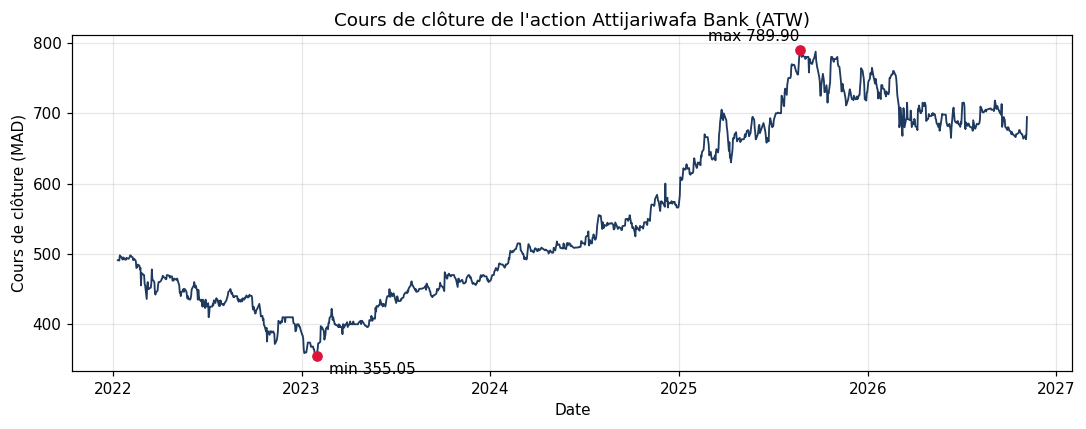

In [82]:
# Graphique 1 : évolution du cours de clôture
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df["Date"], df["Price"], color="#1f3a5f", lw=1.2)
imin, imax = df["Price"].idxmin(), df["Price"].idxmax()
ax.scatter(df.loc[[imin, imax], "Date"], df.loc[[imin, imax], "Price"], color="crimson", zorder=3)
ax.annotate(f"min {df.loc[imin,'Price']:.2f}", (df.loc[imin, "Date"], df.loc[imin, "Price"]), textcoords="offset points", xytext=(8, -12))
ax.annotate(f"max {df.loc[imax,'Price']:.2f}", (df.loc[imax, "Date"], df.loc[imax, "Price"]), textcoords="offset points", xytext=(-60, 6))
ax.set_title("Cours de clôture de l'action Attijariwafa Bank (ATW)")
ax.set_xlabel("Date"); ax.set_ylabel("Cours de clôture (MAD)")
fig.tight_layout(); fig.savefig(FIG / "fig01_cours_cloture.png"); plt.show()

**Interprétation.** Le cours baisse jusqu'à un minimum de 355,05 MAD (30/01/2023), puis monte fortement jusqu'à un maximum de 789,9 MAD (22/08/2025), et recule ensuite : de 736,0 MAD le 14/11/2025 à 694,6 MAD le 05/11/2026. Le niveau du cours n'est pas stationnaire, d'où le choix de travailler avec des rendements et des écarts relatifs plutôt qu'avec des prix. La période de test (à partir du 14/11/2025) est une phase de recul, ce qui favorisera la classe « non-hausse ».

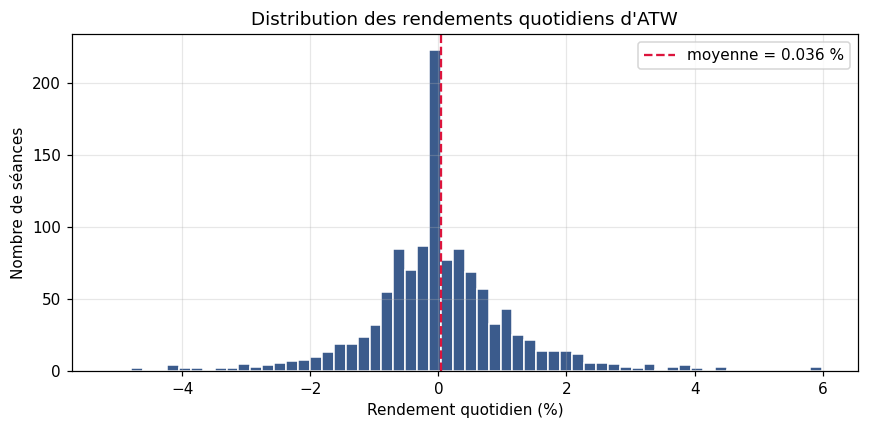

In [83]:
# Graphique 2 : distribution des rendements quotidiens
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(r * 100, bins=60, color="#3b5b8c", edgecolor="white")
ax.axvline(r.mean() * 100, color="crimson", ls="--", label=f"moyenne = {r.mean()*100:.3f} %")
ax.set_title("Distribution des rendements quotidiens d'ATW")
ax.set_xlabel("Rendement quotidien (%)"); ax.set_ylabel("Nombre de séances"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fig02_distribution_rendements.png"); plt.show()

**Interprétation.** Les rendements se concentrent autour de zéro (pic de 9,6 % de séances inchangées) avec des queues épaisses, jusqu'à −5,17 % et +5,99 %. Une loi normale décrit mal ces données, mais ce n'est pas un obstacle pour la régression logistique, qui ne suppose pas la normalité des variables. Le rendement moyen, presque confondu avec zéro, confirme que la direction est difficile à deviner.

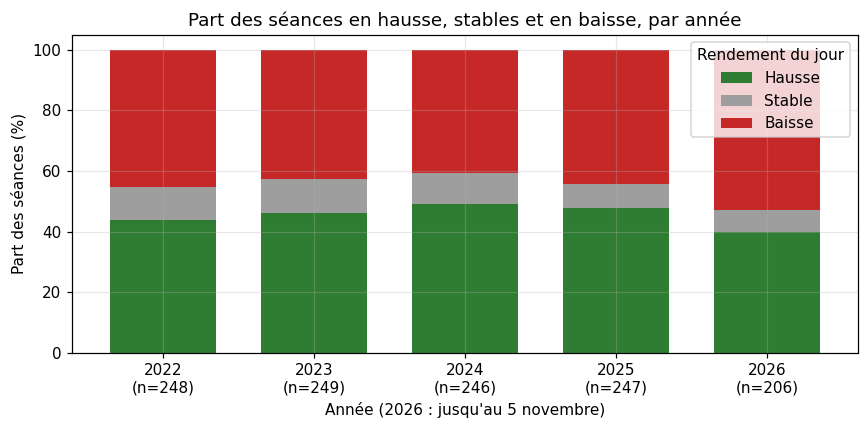

etat,Hausse,Stable,Baisse
annee,,,
2022,44.0,10.9,45.2
2023,46.2,11.2,42.6
2024,49.2,10.2,40.7
2025,47.8,8.1,44.1
2026,39.8,7.3,52.9


In [84]:
# Graphique 3 : répartition hausses / stabilité / baisses par année (rendement du jour)
tmp = pd.DataFrame({"annee": df["Date"].dt.year, "r": rend}).dropna()
tmp["etat"] = np.select([tmp["r"] > 0, tmp["r"] < 0], ["Hausse", "Baisse"], default="Stable")
rep = pd.crosstab(tmp["annee"], tmp["etat"], normalize="index")[["Hausse", "Stable", "Baisse"]] * 100
n_an = tmp.groupby("annee").size()
fig, ax = plt.subplots(figsize=(8, 4))
rep.plot(kind="bar", stacked=True, ax=ax, color=["#2e7d32", "#9e9e9e", "#c62828"], width=.7)
ax.set_xticklabels([f"{a}\n(n={n_an[a]})" for a in rep.index], rotation=0)
ax.set_title("Part des séances en hausse, stables et en baisse, par année")
ax.set_xlabel("Année (2026 : jusqu'au 5 novembre)"); ax.set_ylabel("Part des séances (%)"); ax.legend(title="Rendement du jour")
fig.tight_layout(); fig.savefig(FIG / "fig03_hausses_baisses_par_annee.png"); plt.show()
display(rep.round(1))

**Interprétation.** La part de séances en hausse varie peu de 2022 à 2025 (de 44,0 % à 49,2 %) puis tombe à 39,8 % en 2026, où 52,9 % des séances sont en baisse. La classe majoritaire n'est donc pas stable : la référence « toujours non-hausse » sera difficile à battre en 2026. C'est aussi un premier signe de changement de régime entre l'apprentissage et le test.

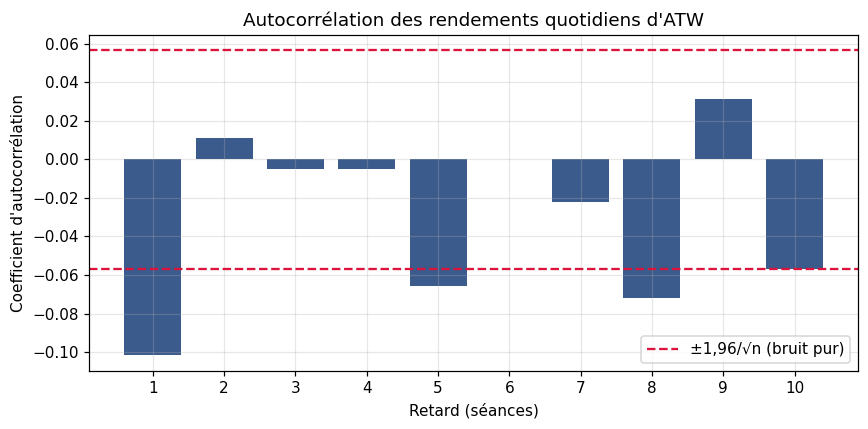

Autocorrélations : [np.float64(-0.102), np.float64(0.011), np.float64(-0.005), np.float64(-0.005), np.float64(-0.066), np.float64(0.0), np.float64(-0.022), np.float64(-0.072), np.float64(0.031), np.float64(-0.057)] | bande : 0.057
Retards hors de la bande : [1, 5, 8, 10]


In [85]:
# Graphique 4 : autocorrélation des rendements (lien direct avec la marche aléatoire)
lags = range(1, 11)
acf = [r.autocorr(k) for k in lags]
bande = 1.96 / np.sqrt(len(r))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(list(lags), acf, color="#3b5b8c")
ax.axhline(bande, color="crimson", ls="--", label="±1,96/√n (bruit pur)"); ax.axhline(-bande, color="crimson", ls="--")
ax.set_title("Autocorrélation des rendements quotidiens d'ATW")
ax.set_xlabel("Retard (séances)"); ax.set_ylabel("Coefficient d'autocorrélation"); ax.set_xticks(list(lags)); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fig04_autocorrelation.png"); plt.show()
print("Autocorrélations :", [round(a, 3) for a in acf], "| bande :", round(bande, 3))
print("Retards hors de la bande :", [k for k, a in zip(lags, acf) if abs(a) > bande])

**Interprétation.** L'autocorrélation de premier ordre est de −0,10, au-delà de la bande de bruit de ±0,057 ; les retards 5, 8 et 10 en sortent aussi de très peu. Sur 10 retards testés, environ une demi-sortie de bande est attendue par hasard (10 × 5 %) ; avec 4 sorties, il y a peut-être une faible corrélation négative, mais un coefficient de −0,10 explique au plus 1 % de la variance du lendemain. C'est cohérent avec une marche aléatoire presque parfaite.

**Conclusion de l'exploration.** Les données sont propres, le rendement du lendemain est dominé par le bruit, la classe « non-hausse » est majoritaire (et davantage en 2026) et les rendements passés sont très faiblement corrélés entre eux. On s'attend donc à un signal très faible, et la référence naïve sera difficile à dépasser.

## 4. Préparation

- **Variables.** Neuf variables à la clôture de $t$ : $r_t$, $r_{t-1}$, $r_{t-2}$, $r_{t-3}$, $r_{t-5}$, les écarts relatifs aux moyennes mobiles de 5 et 10 jours, et les volatilités sur 5 et 10 jours. Les moyennes mobiles sont exprimées en écart relatif pour éviter une variable de niveau non stationnaire.
- **Cible.** Le rendement de $t+1$ est obtenu par `shift(-1)`, puis les lignes incomplètes sont retirées : 10 au début (retards, fenêtres) et 1 à la fin (pas de lendemain), soit 1 186 observations.
- **Valeurs manquantes.** Aucune dans le fichier ; seuls les retards créent des vides, traités en retirant les lignes concernées (aucune imputation).
- **Valeurs extrêmes.** Conservées (section 3).

In [86]:
# Construction des variables explicatives (passé seulement) et de la cible
VARIABLES = ["ret_t", "ret_lag1", "ret_lag2", "ret_lag3", "ret_lag5", "ma5_ratio", "ma10_ratio", "vol5", "vol10"]

def construire_variables(prix):
    """Variables à la clôture de t, calculées uniquement avec des prix jusqu'à t."""
    r = prix.pct_change()                                   # r_t = P_t / P_(t-1) - 1
    X = pd.DataFrame({"ret_t": r})
    for k in (1, 2, 3, 5):
        X[f"ret_lag{k}"] = r.shift(k)                      # shift(k) avec k > 0 : passé
    X["ma5_ratio"] = prix / prix.rolling(5).mean() - 1      # fenêtre qui se termine en t
    X["ma10_ratio"] = prix / prix.rolling(10).mean() - 1
    X["vol5"] = r.rolling(5).std()
    X["vol10"] = r.rolling(10).std()
    return X

X_all = construire_variables(df["Price"])
data = pd.concat([df[["Date", "Price"]], X_all], axis=1)
data["pos"] = np.arange(len(df))                            # position d'origine (pour les tests)
data["ret_suivant"] = X_all["ret_t"].shift(-1)              # rendement de t+1 (décalé vers le futur)
data["cible"] = (data["ret_suivant"] > 0).astype(int)       # 1 si hausse en t+1, 0 sinon (baisse ou stabilité)
n_avant = len(data)
data = data.dropna(subset=VARIABLES + ["ret_suivant"]).reset_index(drop=True)   # lignes incomplètes retirées
print(f"{n_avant} séances -> {len(data)} observations exploitables ({n_avant - len(data)} lignes retirées : "
      f"10 premières (retards, fenêtres) + dernière (pas de lendemain))")
print(f"Part de hausses (cible = 1) : {data['cible'].mean():.1%} | cible = 0 : {1 - data['cible'].mean():.1%}")
print(f"Dont rendements suivants exactement nuls (classés 0) : {(data['ret_suivant'] == 0).sum()}")

1197 séances -> 1186 observations exploitables (11 lignes retirées : 10 premières (retards, fenêtres) + dernière (pas de lendemain))
Part de hausses (cible = 1) : 45.7% | cible = 0 : 54.3%
Dont rendements suivants exactement nuls (classés 0) : 113


In [87]:
# Preuve de l'alignement : quelques lignes (date, variables, cible)
cols = ["Date", "Price", "ret_t", "ma10_ratio", "ret_suivant", "cible"]
display(data[cols].head(5).round(5))

# Recalcul manuel d'une ligne à partir des prix bruts
k = 200
t = data.loc[k]
p = df["Price"]
pos = int(t["pos"])
print(f"Ligne du {t['Date'].date()} (position {pos}) :")
print("  ret_t         =", round(p[pos] / p[pos - 1] - 1, 6), "| dans data :", round(t["ret_t"], 6))
print("  ma10_ratio    =", round(p[pos] / p[pos - 9:pos + 1].mean() - 1, 6), "| dans data :", round(t["ma10_ratio"], 6))
print("  ret_suivant   =", round(p[pos + 1] / p[pos] - 1, 6), "| dans data :", round(t["ret_suivant"], 6),
      "-> cible =", int(t["cible"]))

,Date,Price,ret_t,ma10_ratio,ret_suivant,cible
0,2022-01-25,492.20,0.00041,-0.00224,-0.00091,0
1,2022-01-26,491.75,-0.00091,-0.00330,0.00559,1
2,2022-01-27,494.50,0.00559,0.00148,-0.00121,0
3,2022-01-28,493.90,-0.00121,0.00109,-0.00172,0
4,2022-01-31,493.05,-0.00172,-0.00023,0.00213,1


Ligne du 2022-11-07 (position 210) :
  ret_t         = 0.005026 | dans data : 0.005026
  ma10_ratio    = 0.004107 | dans data : 0.004107
  ret_suivant   = -0.005514 | dans data : -0.005514 -> cible = 0


**Alignement.** Chaque ligne porte les variables connues à la clôture de $t$ et la cible de $t+1$ : par exemple la ligne du 25/01/2022 a un rendement suivant de −0,00091, donc cible 0. Le recalcul manuel d'une ligne à partir des prix bruts redonne exactement les mêmes valeurs.

In [88]:
# Test automatique d'absence de fuite : une variable calculée avec les prix jusqu'à t seulement
# doit être identique à celle calculée avec toute la série.
rng = np.random.default_rng(GRAINE)
positions = rng.choice(data["pos"].values, size=150, replace=False)
for pos in positions:
    partielle = construire_variables(df["Price"].iloc[: pos + 1]).iloc[-1]      # aucune info postérieure à t
    complete = X_all.iloc[pos]
    assert np.allclose(partielle.values.astype(float), complete.values.astype(float), equal_nan=True), pos
    ligne = data.loc[data["pos"] == pos].iloc[0]
    assert int(df["Price"].iloc[pos + 1] / df["Price"].iloc[pos] - 1 > 0) == ligne["cible"], pos
print(f"OK : {len(positions)} positions testées. Variables = fonction du passé seulement ; cible = signe du rendement de t+1.")

OK : 150 positions testées. Variables = fonction du passé seulement ; cible = signe du rendement de t+1.


**Prévention des fuites.** Ce test recalcule les variables de 150 séances tirées au hasard en n'utilisant que les prix jusqu'à $t$, et vérifie qu'elles sont identiques à celles de la série complète : une variable qui utiliserait le futur échouerait. Il vérifie aussi que la cible est bien le signe du rendement de $t+1$. Les statistiques du scaler sont apprises sur l'apprentissage seulement, via un `Pipeline` (voir plus bas).

In [89]:
# Découpage chronologique en trois blocs, avec une ligne d'écart (embargo) à chaque frontière
n = len(data)
i1, i2 = int(0.6 * n), int(0.8 * n)
idx_train = np.arange(0, i1 - 1)          # apprentissage
idx_val   = np.arange(i1, i2 - 1)         # validation
idx_test  = np.arange(i2, n)              # test (20 % les plus récents)
idx_pre   = np.arange(0, i2 - 1)          # apprentissage + validation (pour le réentraînement final)

X, y = data[VARIABLES], data["cible"]
X_tr, y_tr = X.iloc[idx_train], y.iloc[idx_train]
X_va, y_va = X.iloc[idx_val],   y.iloc[idx_val]
X_te, y_te = X.iloc[idx_test],  y.iloc[idx_test]
X_pre, y_pre = X.iloc[idx_pre], y.iloc[idx_pre]

blocs = pd.DataFrame([[nom, len(ix), data.loc[ix[0], "Date"].date(), data.loc[ix[-1], "Date"].date(), f"{y.iloc[ix].mean():.1%}"]
                      for nom, ix in [("Apprentissage", idx_train), ("Validation", idx_val), ("Test", idx_test)]],
                     columns=["Bloc", "Observations", "Début", "Fin", "Part de hausses"])
display(blocs)
print("Lignes retirées (embargo) :", [str(data.loc[i, "Date"].date()) for i in (i1 - 1, i2 - 1)])
assert data.loc[idx_train[-1], "Date"] < data.loc[idx_val[0], "Date"] and data.loc[idx_val[-1], "Date"] < data.loc[idx_test[0], "Date"]
print("Contrôle d'ordre chronologique : OK")
print(f"Référence naïve : la classe majoritaire de l'apprentissage est « {'hausse' if y_tr.mean() > .5 else 'non-hausse'} »")

,Bloc,Observations,Début,Fin,Part de hausses
0,Apprentissage,710,2022-01-25,2024-11-27,46.9%
1,Validation,236,2024-11-29,2025-11-12,46.6%
2,Test,238,2025-11-14,2026-11-04,41.2%


Lignes retirées (embargo) : ['2024-11-28', '2025-11-13']
Contrôle d'ordre chronologique : OK
Référence naïve : la classe majoritaire de l'apprentissage est « non-hausse »


**Découpage chronologique (60 % / 20 % / 20 %).** Apprentissage : 710 observations du 25/01/2022 au 27/11/2024 ; validation : 236 du 29/11/2024 au 12/11/2025 ; test : 238 du 14/11/2025 au 04/11/2026 (dates de prédiction). Une ligne d'écart (embargo) est retirée à chaque frontière (28/11/2024 et 13/11/2025) : la cible de la dernière ligne d'un bloc est le rendement du jour qui est justement la variable `ret_t` de la première ligne du bloc suivant. Aucun mélange aléatoire. La part de hausses passe de 46,9 % (apprentissage) à 46,6 % (validation) puis 41,2 % (test) : la distribution change à la fin.

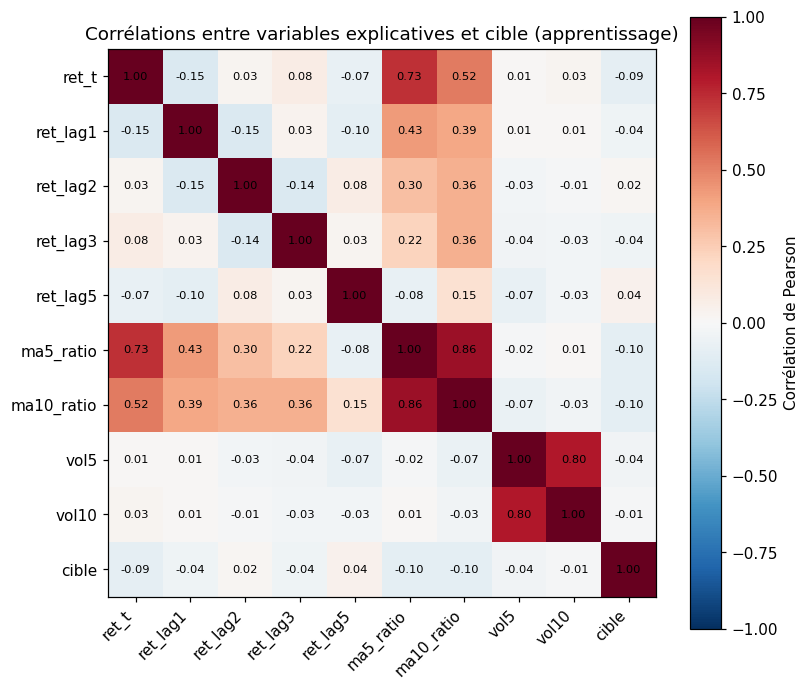

Corrélation de chaque variable avec la cible :
ret_t        -0.092
ret_lag1     -0.041
ret_lag2      0.021
ret_lag3     -0.040
ret_lag5      0.044
ma5_ratio    -0.097
ma10_ratio   -0.098
vol5         -0.035
vol10        -0.013
Corrélation ma5_ratio / ma10_ratio : 0.858


In [90]:
# Graphique 5 : corrélations (calculées sur l'apprentissage seulement)
corr = data.loc[idx_train, VARIABLES + ["cible"]].corr()
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5)
fig.colorbar(im, ax=ax, label="Corrélation de Pearson")
ax.set_title("Corrélations entre variables explicatives et cible (apprentissage)")
fig.tight_layout(); fig.savefig(FIG / "fig05_correlations.png"); plt.show()
print("Corrélation de chaque variable avec la cible :"); print(corr["cible"].drop("cible").round(3).to_string())
print("Corrélation ma5_ratio / ma10_ratio :", round(corr.loc["ma5_ratio", "ma10_ratio"], 3))

**Interprétation.** Les corrélations avec la cible sont toutes faibles : au plus 0,10 en valeur absolue (−0,098 pour `ma10_ratio`, −0,097 pour `ma5_ratio`, −0,092 pour `ret_t`). Le signe négatif correspond à un léger retour à la moyenne. Les deux moyennes mobiles sont fortement corrélées entre elles (0,858) : leurs coefficients, pris séparément, seront peu fiables. Aucune variable ne sépare nettement hausses et non-hausses, ce qui annonce une prédiction difficile.

In [91]:
# Démonstration : le scaler est ajusté sur l'apprentissage seulement
sc = StandardScaler().fit(X_tr)
resume = pd.DataFrame({"moyenne (apprentissage)": sc.mean_, "écart-type (apprentissage)": sc.scale_,
                       "moyenne de la validation après transformation": sc.transform(X_va).mean(axis=0)}, index=VARIABLES)
display(resume.round(4))
data_out = data.drop(columns=["pos"]).copy()
data_out["bloc"] = "embargo"
for nom, ix in [("train", idx_train), ("validation", idx_val), ("test", idx_test)]:
    data_out.loc[ix, "bloc"] = nom
data_out.to_csv(DATA_PROC / "atw_variables_cible.csv", index=False)
print("Fichier enregistré :", (DATA_PROC / "atw_variables_cible.csv").relative_to(RACINE))

,moyenne (apprentissage),écart-type (apprentissage),moyenne de la validation après transformation
ret_t,0.0003,0.0115,0.0727
ret_lag1,0.0003,0.0114,0.0733
ret_lag2,0.0003,0.0114,0.0848
ret_lag3,0.0003,0.0114,0.0983
ret_lag5,0.0003,0.0114,0.0905
ma5_ratio,0.0004,0.0115,0.1521
ma10_ratio,0.0010,0.0170,0.2520
vol5,0.0096,0.0066,0.2372
vol10,0.0102,0.0056,0.3659


Fichier enregistré : data/processed/atw_variables_cible.csv


**Standardisation.** Elle est nécessaire pour la régression logistique : la pénalité $\ell_2$ dépend de l'échelle des variables (les écarts-types vont de 0,0056 pour `vol10` à 0,0170 pour `ma10_ratio`) et les coefficients ne sont comparables que standardisés. La forêt aléatoire, fondée sur des seuils, n'en a pas besoin. Le tableau montre que le scaler utilise la moyenne et l'écart-type de l'apprentissage : appliqué à la validation, il ne donne pas des moyennes nulles (de 0,07 à 0,37), signe qu'il n'a pas été réajusté sur ces données.

## 5. Algorithme

**Régression logistique** (*Logistic Regression*, n°8) : apprentissage supervisé, classification binaire, modèle linéaire probabiliste. Le modèle calcule un score linéaire des variables standardisées, puis le transforme en probabilité de hausse avec la fonction sigmoïde :
$$P(y_t = 1 \mid \mathbf z_t) = \frac{1}{1 + e^{-(\beta_0 + \boldsymbol\beta^\top \mathbf z_t)}}$$
où $\mathbf z_t$ est le vecteur des 9 variables standardisées, $\beta_0$ l'ordonnée à l'origine et $\boldsymbol\beta$ le vecteur des coefficients. L'apprentissage minimise une perte logistique pénalisée :
$$\min_{\beta_0,\boldsymbol\beta}\ \tfrac12\lVert\boldsymbol\beta\rVert_2^2 + C\sum_{i=1}^{n}\ln\!\big(1+e^{-\tilde y_i(\beta_0+\boldsymbol\beta^\top\mathbf z_i)}\big),\qquad \tilde y_i = 2y_i - 1,$$
avec $n$ le nombre d'observations d'apprentissage et $C$ l'inverse de la force de régularisation. Une hausse est prédite si la probabilité dépasse 0,5.

- **Paramètres appris :** $\beta_0$ et les 9 coefficients $\boldsymbol\beta$. **Hyperparamètres :** $C$ (réglé sur $\{0{,}01 ; 0{,}1 ; 1 ; 10 ; 100\}$), la pénalité (fixée à $\ell_2$), le seuil de décision (fixé à 0,5) et `max_iter`. Un $C$ petit écrase les coefficients vers zéro (modèle rigide, probabilités proches de la fréquence moyenne) ; un $C$ grand laisse le modèle coller aux données d'apprentissage.
- **Avantages :** rapide, interprétable, peu sujet au surapprentissage, sort une probabilité. **Limites :** frontière linéaire, coefficients instables si les variables sont corrélées (ici `ma5_ratio` et `ma10_ratio`), sensible à l'échelle.
- **Pourquoi ce choix.** Les rendements journaliers sont presque du bruit : avec environ 950 observations et 9 variables, un modèle simple à faible capacité est le plus raisonnable, et c'est la référence habituelle des études de prévisibilité. On peut en outre l'expliquer coefficient par coefficient.
- **Pourquoi pas la forêt aléatoire (n°12) comme modèle principal.** Elle capte des relations non linéaires, mais sur peu de données bruitées elle apprend du bruit (voir courbes de validation), dépend de la graine et s'interprète moins bien. Elle est conservée comme comparaison. Le gradient boosting (n°14, n°16) souffre des mêmes risques.

## 6. Protocole expérimental

- **Découpage chronologique** (section 4) : apprentissage 25/01/2022 → 27/11/2024 (710 obs.), validation 29/11/2024 → 12/11/2025 (236), test 14/11/2025 → 04/11/2026 (238). Le test n'est utilisé qu'une fois, pour les modèles retenus, après réentraînement sur apprentissage + validation (947 obs., hyperparamètres inchangés).
- **Référence naïve :** la classe majoritaire de l'apprentissage, ici « non-hausse » (`DummyClassifier`). Elle prédit toujours 0 : son accuracy est la part de non-hausses du jeu évalué et sa balanced accuracy vaut 0,5 par construction.
- **Réglage :** `GridSearchCV` avec `TimeSeriesSplit(5)` dans l'apprentissage uniquement, critère *balanced accuracy*. **Configurations essayées, toutes déclarées :** 5 valeurs de $C$ pour la régression logistique et 9 combinaisons (`max_depth` ∈ {3, 5, 8} × `min_samples_leaf` ∈ {10, 20, 40}, 300 arbres) pour la forêt, soit **14 configurations**, plus la référence. Des diagnostics supplémentaires sont aussi calculés sur le test (graines, sous-périodes, sensibilité à $C$, simulation de frais) ; ils servent à juger la robustesse, jamais à choisir un modèle.
- **Métriques.** *Balanced accuracy* (principale) : moyenne du rappel sur chaque classe ; 0,5 signifie aucune information, alors que l'*accuracy* d'une règle triviale est élevée quand les classes sont déséquilibrées (58,8 % sur le test). Secondaires : *accuracy* (part de prédictions justes), *precision*, *recall* et *F1* de la classe « hausse », *ROC-AUC* (qualité du classement des probabilités, indépendante du seuil ; 0,5 = hasard) et matrice de confusion.
- **Incertitude :** moyenne et écart-type des plis de validation croisée, et intervalle à 95 % par bootstrap par blocs de 10 séances (2 000 tirages) pour respecter la dépendance entre jours voisins.

In [92]:
# Protocole : référence, pipelines, grilles, métriques
tscv = TimeSeriesSplit(n_splits=5)

def pipe_lr():
    return Pipeline([("scaler", StandardScaler()), ("lr", LogisticRegression(max_iter=1000, random_state=GRAINE))])

def modele_rf():
    return RandomForestClassifier(n_estimators=300, random_state=GRAINE, n_jobs=-1)

GRILLE_LR = {"lr__C": [0.01, 0.1, 1, 10, 100]}                                  # 5 valeurs
GRILLE_RF = {"max_depth": [3, 5, 8], "min_samples_leaf": [10, 20, 40]}          # 3 x 3 = 9 combinaisons
N_CONFIG = len(GRILLE_LR["lr__C"]) + 9
print(f"Configurations essayées : {len(GRILLE_LR['lr__C'])} (régression logistique) + 9 (forêt aléatoire) = {N_CONFIG}, plus la référence.")

def metriques(y_vrai, pred, proba):
    return {"Accuracy": accuracy_score(y_vrai, pred), "Precision": precision_score(y_vrai, pred, zero_division=0),
            "Recall": recall_score(y_vrai, pred), "F1": f1_score(y_vrai, pred),
            "Balanced acc.": balanced_accuracy_score(y_vrai, pred), "ROC-AUC": roc_auc_score(y_vrai, proba)}

Configurations essayées : 5 (régression logistique) + 9 (forêt aléatoire) = 14, plus la référence.


In [93]:
# Réglage des hyperparamètres : TimeSeriesSplit(5) à l'intérieur de l'apprentissage uniquement
gs_lr = GridSearchCV(pipe_lr(), GRILLE_LR, cv=tscv, scoring="balanced_accuracy").fit(X_tr, y_tr)
gs_rf = GridSearchCV(modele_rf(), GRILLE_RF, cv=tscv, scoring="balanced_accuracy").fit(X_tr, y_tr)

for nom, gs in [("Régression logistique", gs_lr), ("Forêt aléatoire", gs_rf)]:
    res = pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
    res.columns = ["Paramètres", "BA moyenne (CV)", "Écart-type (CV)", "Rang"]
    print(f"\n{nom} : meilleure configuration = {gs.best_params_} | BA CV = {gs.best_score_:.3f}")
    display(res.sort_values("Rang").round(4))


Régression logistique : meilleure configuration = {'lr__C': 0.01} | BA CV = 0.526


,Paramètres,BA moyenne (CV),Écart-type (CV),Rang
0,{'lr__C': 0.01},0.5261,0.0296,1
1,{'lr__C': 0.1},0.5100,0.0346,2
2,{'lr__C': 1},0.5037,0.0337,3
3,{'lr__C': 10},0.4960,0.0321,4
4,{'lr__C': 100},0.4957,0.0319,5



Forêt aléatoire : meilleure configuration = {'max_depth': 3, 'min_samples_leaf': 10} | BA CV = 0.519


,Paramètres,BA moyenne (CV),Écart-type (CV),Rang
0,"{'max_depth': 3, 'min_samples_leaf': 10}",0.5191,0.0550,1
4,"{'max_depth': 5, 'min_samples_leaf': 20}",0.5087,0.0532,2
6,"{'max_depth': 8, 'min_samples_leaf': 10}",0.5083,0.0484,3
1,"{'max_depth': 3, 'min_samples_leaf': 20}",0.5074,0.0554,4
3,"{'max_depth': 5, 'min_samples_leaf': 10}",0.5058,0.0538,5
7,"{'max_depth': 8, 'min_samples_leaf': 20}",0.5039,0.0535,6
8,"{'max_depth': 8, 'min_samples_leaf': 40}",0.4966,0.0342,7
5,"{'max_depth': 5, 'min_samples_leaf': 40}",0.4948,0.0350,8
2,"{'max_depth': 3, 'min_samples_leaf': 40}",0.4931,0.0323,9


**Lecture.** La validation croisée retient $C = 0{,}01$ pour la régression logistique (balanced accuracy de 0,526 ± 0,030) et `max_depth = 3`, `min_samples_leaf = 10` pour la forêt (0,519 ± 0,055). Les écarts entre configurations (de 0,496 à 0,526) sont du même ordre que les écarts-types : le réglage distingue mal les modèles.

## 7. Résultats

In [94]:
# Résultats en validation (modèles ajustés sur l'apprentissage seulement)
base_tr = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
modeles_val = {"Référence (classe majoritaire)": base_tr, "Régression logistique (principal)": gs_lr.best_estimator_,
               "Forêt aléatoire (comparaison)": gs_rf.best_estimator_}
tab_val = pd.DataFrame({nom: metriques(y_va, m.predict(X_va), m.predict_proba(X_va)[:, 1]) for nom, m in modeles_val.items()}).T
display(tab_val.round(3))
print("Validation : n =", len(y_va), "| part de hausses :", f"{y_va.mean():.1%}")

,Accuracy,Precision,Recall,F1,Balanced acc.,ROC-AUC
Référence (classe majoritaire),0.534,0.000,0.000,0.000,0.500,0.500
Régression logistique (principal),0.441,0.296,0.145,0.195,0.422,0.451
Forêt aléatoire (comparaison),0.517,0.455,0.182,0.260,0.496,0.483


Validation : n = 236 | part de hausses : 46.6%


**Validation.** Sur le bloc de validation (29/11/2024 → 12/11/2025, période haussière), les deux modèles font moins bien que la référence : balanced accuracy de 0,422 (régression logistique) et 0,488 (forêt), ROC-AUC inférieure à 0,5. Le léger signal vu en validation croisée sur l'apprentissage (0,526) ne se retrouve pas ici : s'il existe, il n'est pas stable d'une période à l'autre.

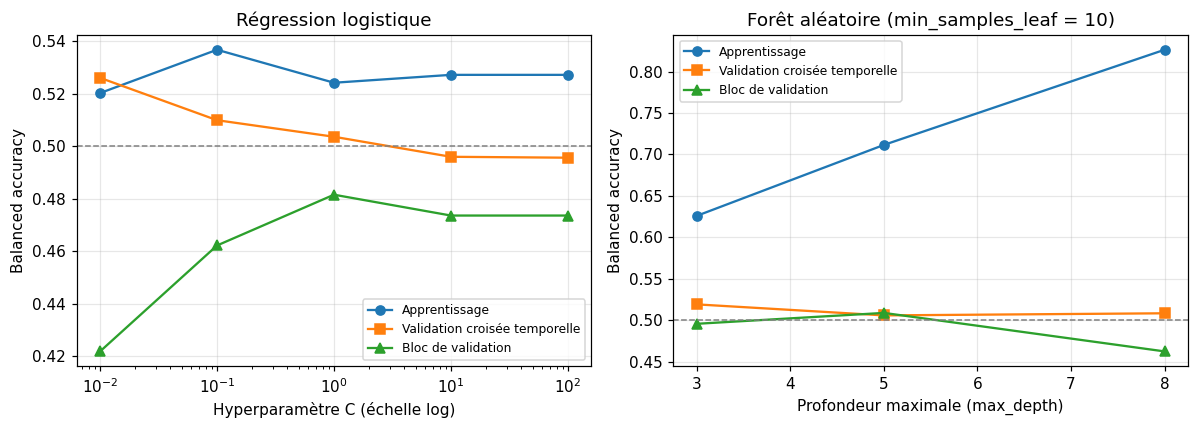

,C,train,cv,val
0,0.01,0.520,0.526,0.422
1,0.10,0.537,0.510,0.462
2,1.00,0.524,0.504,0.482
3,10.00,0.527,0.496,0.474
4,100.00,0.527,0.496,0.474


,max_depth,train,cv,val
0,3,0.626,0.519,0.496
1,5,0.712,0.506,0.509
2,8,0.826,0.508,0.462


In [95]:
# Courbes de validation : score selon un hyperparamètre (surapprentissage)
def courbe(fabrique, nom_param, valeurs):
    lignes = []
    for v in valeurs:
        m = fabrique(v)
        lignes.append({"v": v, "train": balanced_accuracy_score(y_tr, m.fit(X_tr, y_tr).predict(X_tr)),
                       "cv": cross_val_score(fabrique(v), X_tr, y_tr, cv=tscv, scoring="balanced_accuracy").mean(),
                       "val": balanced_accuracy_score(y_va, m.predict(X_va))})
    return pd.DataFrame(lignes)

c_lr = courbe(lambda v: pipe_lr().set_params(lr__C=v), "C", GRILLE_LR["lr__C"])
prof_leaf = gs_rf.best_params_["min_samples_leaf"]
c_rf = courbe(lambda v: modele_rf().set_params(max_depth=v, min_samples_leaf=prof_leaf), "max_depth", GRILLE_RF["max_depth"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, c, titre, xl, logx in [(axes[0], c_lr, "Régression logistique", "Hyperparamètre C (échelle log)", True),
                               (axes[1], c_rf, f"Forêt aléatoire (min_samples_leaf = {prof_leaf})", "Profondeur maximale (max_depth)", False)]:
    for col, lab, st in [("train", "Apprentissage", "o-"), ("cv", "Validation croisée temporelle", "s-"), ("val", "Bloc de validation", "^-")]:
        ax.plot(c["v"], c[col], st, label=lab)
    ax.axhline(0.5, color="gray", ls="--", lw=1)
    if logx: ax.set_xscale("log")
    ax.set_title(titre); ax.set_xlabel(xl); ax.set_ylabel("Balanced accuracy"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig06_courbes_validation.png"); plt.show()
display(c_lr.round(3).rename(columns={"v": "C"})); display(c_rf.round(3).rename(columns={"v": "max_depth"}))

**Courbes de validation.** Pour la régression logistique, les scores restent entre 0,42 et 0,54 quel que soit $C$ ; le meilleur $C$ en validation croisée ($C = 0{,}01$, 0,526) est le pire sur le bloc de validation (0,422), signe que ces écarts de quelques points sont du bruit. Pour la forêt, la balanced accuracy d'apprentissage monte de 0,626 à 0,828 quand la profondeur passe de 3 à 8, alors que la validation croisée reste vers 0,51 : c'est du surapprentissage.

In [96]:
# ÉVALUATION FINALE SUR LE TEST : utilisé une seule fois pour les modèles retenus.
# Réentraînement sur apprentissage + validation avec les hyperparamètres choisis en validation croisée.
final_base = DummyClassifier(strategy="most_frequent").fit(X_pre, y_pre)
final_lr = clone(gs_lr.best_estimator_).fit(X_pre, y_pre)
final_rf = clone(gs_rf.best_estimator_).fit(X_pre, y_pre)
modeles_test = {"Référence (classe majoritaire)": final_base, "Régression logistique (principal)": final_lr,
                "Forêt aléatoire (comparaison)": final_rf}
pred_te = {nom: m.predict(X_te) for nom, m in modeles_test.items()}
proba_te = {nom: m.predict_proba(X_te)[:, 1] for nom, m in modeles_test.items()}
tab_test = pd.DataFrame({nom: metriques(y_te, pred_te[nom], proba_te[nom]) for nom in modeles_test}).T
display(tab_test.round(3))
print(f"Test : n = {len(y_te)} | part de hausses : {y_te.mean():.1%} | taux de hausses prédites :",
      {nom.split(' (')[0]: round(float(p.mean()), 3) for nom, p in pred_te.items()})

,Accuracy,Precision,Recall,F1,Balanced acc.,ROC-AUC
Référence (classe majoritaire),0.588,0.000,0.000,0.000,0.500,0.500
Régression logistique (principal),0.597,0.528,0.194,0.284,0.536,0.551
Forêt aléatoire (comparaison),0.597,0.520,0.265,0.351,0.547,0.567


Test : n = 238 | part de hausses : 41.2% | taux de hausses prédites : {'Référence': 0.0, 'Régression logistique': 0.151, 'Forêt aléatoire': 0.21}


**Test.** La référence atteint 0,588 d'accuracy (140 prédictions justes sur 238). La régression logistique obtient 0,597 (142 justes) et une balanced accuracy de 0,536 ; la forêt 0,601 (143 justes) et 0,551. L'avance en accuracy est de 2 à 3 séances sur 238. Les modèles prédisent une hausse très rarement (15,1 % et 20,6 % des jours, contre 41,2 % de hausses réelles), d'où un recall faible (0,194 et 0,265) pour une precision proche de 0,53.

In [97]:
# Apprentissage vs validation vs test : surapprentissage ?
lignes = []
for nom, m_tr, m_fin in [("Régression logistique", gs_lr.best_estimator_, final_lr), ("Forêt aléatoire", gs_rf.best_estimator_, final_rf)]:
    lignes.append([nom, balanced_accuracy_score(y_tr, m_tr.predict(X_tr)), balanced_accuracy_score(y_va, m_tr.predict(X_va)),
                   balanced_accuracy_score(y_pre, m_fin.predict(X_pre)), balanced_accuracy_score(y_te, m_fin.predict(X_te))])
gen = pd.DataFrame(lignes, columns=["Modèle", "BA apprentissage", "BA validation", "BA apprentissage+validation (final)", "BA test"])
display(gen.round(3))

,Modèle,BA apprentissage,BA validation,BA apprentissage+validation (final),BA test
0,Régression logistique,0.520,0.422,0.526,0.536
1,Forêt aléatoire,0.626,0.496,0.609,0.547


**Surapprentissage.** La régression logistique a des scores proches sur tous les blocs (0,520 en apprentissage, 0,536 en test) : elle ne surapprend pas, mais n'apprend presque rien. La forêt passe de 0,626 (apprentissage) et 0,609 (apprentissage + validation) à 0,488 en validation et 0,551 en test : un écart de 6 à 14 points trahit un surapprentissage.

In [98]:
# Incertitude : bootstrap par blocs (blocs de 10 séances, 2000 tirages) sur les prédictions du test
L, B = 10, 2000
yv = y_te.values

def indices_bootstrap(n, L, B, graine=GRAINE):
    rng = np.random.default_rng(graine)
    nb = int(np.ceil(n / L))
    return [np.concatenate([np.arange(s, s + L) for s in rng.integers(0, n - L + 1, nb)])[:n] for _ in range(B)]

indices = indices_bootstrap(len(yv), L, B)       # mêmes tirages pour tous les modèles
pb = pred_te["Référence (classe majoritaire)"]
res_ic = {}
for nom in ["Régression logistique (principal)", "Forêt aléatoire (comparaison)"]:
    p = pred_te[nom]
    ba_boot = [balanced_accuracy_score(yv[i], p[i]) for i in indices]
    diff_boot = [accuracy_score(yv[i], p[i]) - accuracy_score(yv[i], pb[i]) for i in indices]
    res_ic[nom] = {"ba": balanced_accuracy_score(yv, p), "ic_ba": np.percentile(ba_boot, [2.5, 97.5]),
                   "diff_acc": accuracy_score(yv, p) - accuracy_score(yv, pb), "ic_diff_acc": np.percentile(diff_boot, [2.5, 97.5])}
    r_ = res_ic[nom]
    print(f"{nom}\n  balanced accuracy = {r_['ba']:.3f}  IC95 % = [{r_['ic_ba'][0]:.3f} ; {r_['ic_ba'][1]:.3f}]"
          f"\n  accuracy - référence = {r_['diff_acc']*100:+.1f} points  IC95 % = [{r_['ic_diff_acc'][0]*100:+.1f} ; {r_['ic_diff_acc'][1]*100:+.1f}]")
    print(f"  nombre de prédictions correctes : {int((p == yv).sum())} / {len(yv)} (référence : {int((pb == yv).sum())})")

# Robustesse du critère 2 à la longueur des blocs (régression logistique)
print("\nBorne basse de l'IC95 % de la BA (régression logistique) selon la longueur des blocs :")
for L_ in (5, 10, 20):
    ib = indices_bootstrap(len(yv), L_, B)
    bas = np.percentile([balanced_accuracy_score(yv[i], pred_te["Régression logistique (principal)"][i]) for i in ib], 2.5)
    print(f"  blocs de {L_:2d} séances : {bas:.3f}")

Régression logistique (principal)
  balanced accuracy = 0.536  IC95 % = [0.502 ; 0.586]
  accuracy - référence = +0.8 points  IC95 % = [-2.5 ; +5.5]
  nombre de prédictions correctes : 142 / 238 (référence : 140)
Forêt aléatoire (comparaison)
  balanced accuracy = 0.547  IC95 % = [0.497 ; 0.594]
  accuracy - référence = +0.8 points  IC95 % = [-4.2 ; +5.9]
  nombre de prédictions correctes : 142 / 238 (référence : 140)

Borne basse de l'IC95 % de la BA (régression logistique) selon la longueur des blocs :
  blocs de  5 séances : 0.497
  blocs de 10 séances : 0.502
  blocs de 20 séances : 0.504


**Incertitude.** La balanced accuracy de la régression logistique (0,536) a un intervalle à 95 % de [0,502 ; 0,586], et la différence d'accuracy avec la référence (+0,8 point, soit 2 prédictions de plus) un intervalle de [−2,5 ; +5,5] qui contient zéro. La borne basse dépend de la longueur des blocs : 0,497 avec des blocs de 5 séances, 0,502 avec 10, 0,504 avec 20. Pour la forêt, l'intervalle [0,497 ; 0,595] contient 0,5.

In [99]:
# Verdict : l'objectif défini en section 1 est-il atteint ?
acc_ref = accuracy_score(yv, pb)
for nom, r_ in res_ic.items():
    c1 = accuracy_score(yv, pred_te[nom]) > acc_ref
    c2 = r_["ic_ba"][0] > 0.5
    print(f"{nom}\n  Critère 1 (accuracy {accuracy_score(yv, pred_te[nom]):.3f} > référence {acc_ref:.3f}) : {'OUI' if c1 else 'NON'}"
          f"\n  Critère 2 (borne basse IC BA = {r_['ic_ba'][0]:.3f} > 0,5) : {'OUI' if c2 else 'NON'}"
          f"\n  => OBJECTIF {'ATTEINT' if (c1 and c2) else 'NON ATTEINT'}\n")

Régression logistique (principal)
  Critère 1 (accuracy 0.597 > référence 0.588) : OUI
  Critère 2 (borne basse IC BA = 0.502 > 0,5) : OUI
  => OBJECTIF ATTEINT

Forêt aléatoire (comparaison)
  Critère 1 (accuracy 0.597 > référence 0.588) : OUI
  Critère 2 (borne basse IC BA = 0.497 > 0,5) : NON
  => OBJECTIF NON ATTEINT



**Verdict sur l'objectif.** Pour le modèle principal, les deux critères fixés en section 1 sont satisfaits au sens strict : accuracy de 0,597 contre 0,588, et borne basse de 0,502 > 0,5. Mais c'est de justesse : l'avance en accuracy représente 2 prédictions sur 238, et le critère 2 bascule sous 0,5 avec un autre choix de longueur de blocs. La forêt ne remplit pas le critère 2.

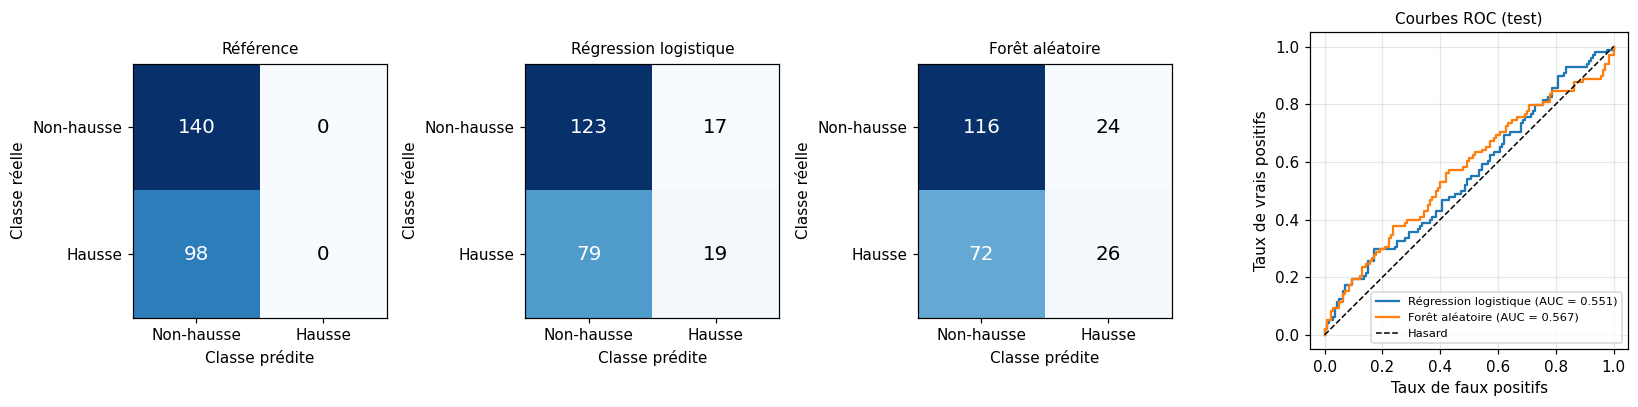

In [100]:
# Graphique 7 : matrices de confusion et courbes ROC sur le test
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 1, 1, 1.25]})
for ax, (nom, p) in zip(axes[:3], pred_te.items()):
    cm = confusion_matrix(y_te, p, labels=[0, 1])
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Non-hausse", "Hausse"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["Non-hausse", "Hausse"])
    ax.set_xlabel("Classe prédite"); ax.set_ylabel("Classe réelle"); ax.set_title(nom.split(" (")[0], fontsize=10)
ax = axes[3]
for nom in ["Régression logistique (principal)", "Forêt aléatoire (comparaison)"]:
    fpr, tpr, _ = roc_curve(y_te, proba_te[nom]); ax.plot(fpr, tpr, label=f"{nom.split(' (')[0]} (AUC = {roc_auc_score(y_te, proba_te[nom]):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Hasard"); ax.set_xlabel("Taux de faux positifs"); ax.set_ylabel("Taux de vrais positifs")
ax.set_title("Courbes ROC (test)", fontsize=10); ax.legend(fontsize=7.5)
fig.tight_layout(); fig.savefig(FIG / "fig07_confusion_roc.png"); plt.show()

**Interprétation.** Les matrices de confusion montrent que les deux modèles ressemblent à la référence : ils prédisent presque toujours « non-hausse » et ne détectent qu'une minorité de hausses réelles (19 sur 98 pour la régression logistique). Les courbes ROC sont proches de la diagonale (AUC de 0,551 et 0,567) : le classement des probabilités est à peine meilleur que le hasard.

,n,acc_modele,acc_reference,part_hausses
mois,,,,
2025-11,10,0.40,0.50,0.50
2025-12,23,0.52,0.48,0.52
2026-01,20,0.70,0.70,0.30
2026-02,20,0.55,0.65,0.35
2026-03,20,0.70,0.50,0.50
2026-04,22,0.55,0.59,0.41
2026-05,17,0.71,0.59,0.41
2026-06,21,0.67,0.67,0.33
2026-07,22,0.55,0.59,0.41


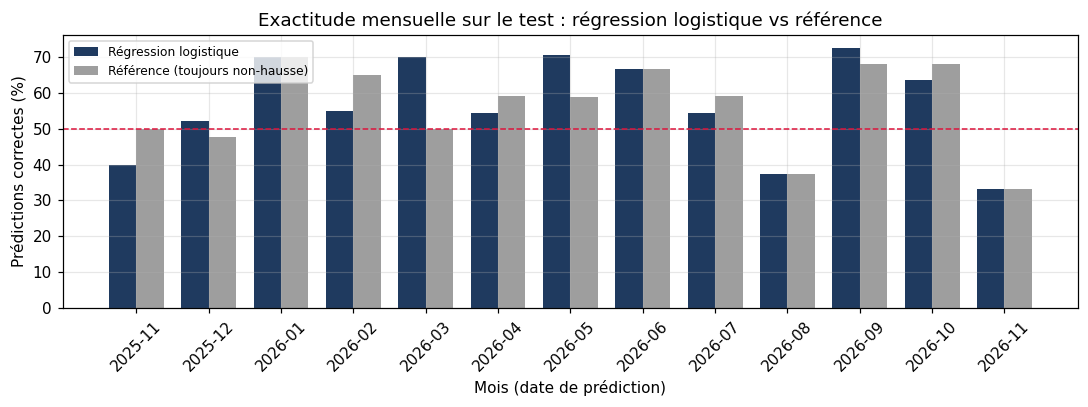

Séances avec |r| > 2 % : 29 | exactitude du modèle sur ces séances : 44.8% | sur les autres : 61.7%
Rendement moyen du lendemain quand le modèle prédit « hausse » : +0.260 % (n = 36) | quand il prédit « non-hausse » : -0.065 % (n = 202)
Faux positifs : 17 | faux négatifs : 79
Les 3 erreurs les plus confiantes (probabilité de hausse la plus éloignée de la réalité) :


,Date,proba,pred,cible,ret_suivant
1090,2026-06-15,0.3672,0,1,0.0041
1103,2026-07-03,0.3923,0,1,0.0003
971,2025-12-18,0.4219,0,1,0.0250


In [101]:
# Analyse des erreurs de la régression logistique (principal) sur le test
nom_lr = "Régression logistique (principal)"
err = data.loc[idx_test, ["Date", "ret_suivant", "cible"]].copy()
err["pred"] = pred_te[nom_lr]; err["proba"] = proba_te[nom_lr]; err["juste"] = (err["pred"] == err["cible"]).astype(int)
err["ref_juste"] = (pb == yv).astype(int)
err["mois"] = err["Date"].dt.to_period("M")
par_mois = err.groupby("mois").agg(n=("juste", "size"), acc_modele=("juste", "mean"), acc_reference=("ref_juste", "mean"), part_hausses=("cible", "mean"))
display(par_mois.round(2))
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(par_mois)); w = .38
ax.bar(x - w / 2, par_mois["acc_modele"] * 100, w, label="Régression logistique", color="#1f3a5f")
ax.bar(x + w / 2, par_mois["acc_reference"] * 100, w, label="Référence (toujours non-hausse)", color="#9e9e9e")
ax.axhline(50, color="crimson", ls="--", lw=1)
ax.set_xticks(x); ax.set_xticklabels(par_mois.index.astype(str), rotation=45)
ax.set_title("Exactitude mensuelle sur le test : régression logistique vs référence")
ax.set_xlabel("Mois (date de prédiction)"); ax.set_ylabel("Prédictions correctes (%)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig08_erreurs_par_mois.png"); plt.show()

gros = err["ret_suivant"].abs() > 0.02
print(f"Séances avec |r| > 2 % : {gros.sum()} | exactitude du modèle sur ces séances : {err.loc[gros, 'juste'].mean():.1%}"
      f" | sur les autres : {err.loc[~gros, 'juste'].mean():.1%}")
print(f"Rendement moyen du lendemain quand le modèle prédit « hausse » : {err.loc[err['pred']==1, 'ret_suivant'].mean()*100:+.3f} %"
      f" (n = {(err['pred']==1).sum()}) | quand il prédit « non-hausse » : {err.loc[err['pred']==0, 'ret_suivant'].mean()*100:+.3f} % (n = {(err['pred']==0).sum()})")
fp, fn = err[(err.pred == 1) & (err.cible == 0)], err[(err.pred == 0) & (err.cible == 1)]
print(f"Faux positifs : {len(fp)} | faux négatifs : {len(fn)}")
print("Les 3 erreurs les plus confiantes (probabilité de hausse la plus éloignée de la réalité) :")
err["erreur_conf"] = np.where(err["juste"] == 0, np.abs(err["proba"] - err["cible"]), 0)
display(err.sort_values("erreur_conf", ascending=False).head(3)[["Date", "proba", "pred", "cible", "ret_suivant"]].round(4))

**Analyse des erreurs (régression logistique).** Le modèle commet surtout des faux négatifs (79 hausses manquées contre 17 fausses alertes). Sur 13 mois de test, il fait mieux que la référence 4 mois, autant 4 mois et moins bien 5 mois : aucun avantage constant (les mois de novembre 2025 et 2026 ne comptent que 10 et 3 séances). Il se trompe davantage les jours de grands mouvements : 44,8 % de prédictions justes sur les 29 séances avec |r| > 2 %, contre 61,7 % sur les autres. Quand il prédit une hausse (36 fois), le rendement moyen du lendemain est de +0,260 %, contre −0,065 % quand il prédit une non-hausse : un indice d'information, mais sur un petit échantillon bruité.

,Coefficient (modèle final),Perte de BA par permutation (moy.),Écart-type
ret_lag1,-0.0019,-0.0077,0.0061
vol10,-0.0002,-0.0117,0.0055
ret_lag3,0.0227,-0.0144,0.0074
vol5,-0.0136,-0.0221,0.0116
ret_lag2,0.0239,-0.0346,0.0129
ma10_ratio,-0.1158,-0.0361,0.0207
ma5_ratio,-0.0150,-0.0393,0.0132
ret_t,-0.0362,-0.0479,0.0153
ret_lag5,0.0027,-0.0506,0.0145


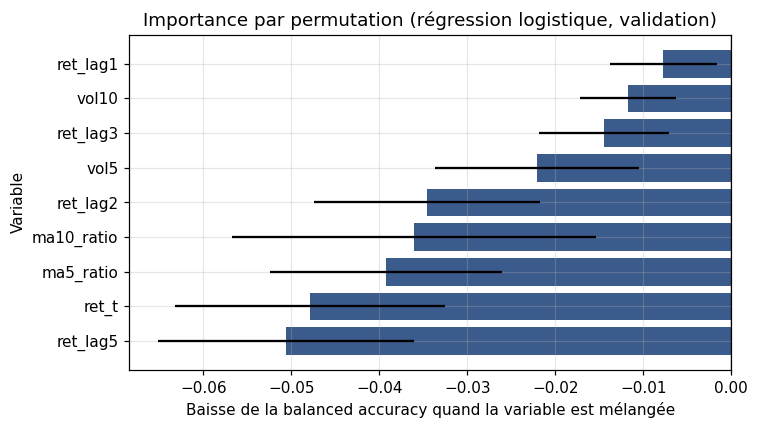

Corrélation ma5_ratio / ma10_ratio (apprentissage) : 0.858


In [102]:
# Interprétation des variables (régression logistique)
lr_final = final_lr.named_steps["lr"]
coefs = pd.Series(lr_final.coef_[0], index=VARIABLES, name="Coefficient (variables standardisées)")
# Importance par permutation, mesurée sur le bloc de validation avec le modèle ajusté sur l'apprentissage
imp = permutation_importance(gs_lr.best_estimator_, X_va, y_va, scoring="balanced_accuracy", n_repeats=30, random_state=GRAINE)
tab_imp = pd.DataFrame({"Coefficient (modèle final)": coefs, "Perte de BA par permutation (moy.)": imp.importances_mean,
                        "Écart-type": imp.importances_std}).sort_values("Perte de BA par permutation (moy.)", ascending=False)
display(tab_imp.round(4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(tab_imp.index[::-1], tab_imp["Perte de BA par permutation (moy.)"][::-1], xerr=tab_imp["Écart-type"][::-1], color="#3b5b8c")
ax.axvline(0, color="k", lw=.8)
ax.set_title("Importance par permutation (régression logistique, validation)")
ax.set_xlabel("Baisse de la balanced accuracy quand la variable est mélangée"); ax.set_ylabel("Variable")
fig.tight_layout(); fig.savefig(FIG / "fig09_importance_permutation.png"); plt.show()
print("Corrélation ma5_ratio / ma10_ratio (apprentissage) :", round(corr.loc["ma5_ratio", "ma10_ratio"], 3))

**Interprétation des variables.** Dans le modèle final, le coefficient le plus marqué est celui de `ma10_ratio` (−0,116), qui va dans le sens d'un retour à la moyenne ; les autres sont presque nuls. Comme `ma5_ratio` et `ma10_ratio` sont corrélées à 0,858, on ne peut pas interpréter chaque coefficient isolément. L'importance par permutation, mesurée sur la validation, est négative pour toutes les variables : mélanger une variable *améliore* légèrement le score, ce qui est cohérent avec un modèle en dessous du hasard sur ce bloc (0,422). Ces importances décrivent le modèle, pas une relation causale.

In [103]:
# Stabilité : deux sous-périodes du test, puis plusieurs graines pour la forêt (diagnostic, pas de sélection)
moitie = len(y_te) // 2
lignes = []
for nom, p in pred_te.items():
    for lab, sl in [("1re moitié du test", slice(0, moitie)), ("2e moitié du test", slice(moitie, None))]:
        lignes.append([nom, lab, len(y_te.iloc[sl]), accuracy_score(y_te.iloc[sl], p[sl]), balanced_accuracy_score(y_te.iloc[sl], p[sl])])
stab = pd.DataFrame(lignes, columns=["Modèle", "Sous-période", "n", "Accuracy", "Balanced acc."])
print("Période 1 :", data.loc[idx_test[0], "Date"].date(), "->", data.loc[idx_test[moitie - 1], "Date"].date(),
      "| Période 2 :", data.loc[idx_test[moitie], "Date"].date(), "->", data.loc[idx_test[-1], "Date"].date())
display(stab.round(3))

bests = {k: v for k, v in gs_rf.best_params_.items()}
res_graines = []
for g in range(10):
    m = modele_rf().set_params(random_state=g, **bests).fit(X_pre, y_pre)
    res_graines.append([g, accuracy_score(y_te, m.predict(X_te)), balanced_accuracy_score(y_te, m.predict(X_te))])
rg = pd.DataFrame(res_graines, columns=["graine", "Accuracy", "Balanced acc."])
print(f"Forêt aléatoire {bests}, 10 graines (0 à 9) : accuracy {rg['Accuracy'].min():.3f}-{rg['Accuracy'].max():.3f}, "
      f"balanced acc. {rg['Balanced acc.'].min():.3f}-{rg['Balanced acc.'].max():.3f} (moyenne {rg['Balanced acc.'].mean():.3f})")

Période 1 : 2025-11-14 -> 2026-05-07 | Période 2 : 2026-05-08 -> 2026-11-04


,Modèle,Sous-période,n,Accuracy,Balanced acc.
0,Référence (classe majoritaire),1re moitié du test,119,0.563,0.500
1,Référence (classe majoritaire),2e moitié du test,119,0.613,0.500
2,Régression logistique (principal),1re moitié du test,119,0.571,0.533
3,Régression logistique (principal),2e moitié du test,119,0.622,0.535
4,Forêt aléatoire (comparaison),1re moitié du test,119,0.597,0.560
5,Forêt aléatoire (comparaison),2e moitié du test,119,0.597,0.535


Forêt aléatoire {'max_depth': 3, 'min_samples_leaf': 10}, 10 graines (0 à 9) : accuracy 0.580-0.622, balanced acc. 0.520-0.568 (moyenne 0.545)


**Stabilité.** Sur les deux moitiés du test, la régression logistique a une balanced accuracy de 0,533 puis 0,535, stable, mais son accuracy (0,571 et 0,622) suit celle de la référence (0,563 et 0,613) : la différence reste très faible. Pour la forêt avec 10 graines, la balanced accuracy varie de 0,520 à 0,568 (moyenne 0,545) et l'accuracy de 0,580 à 0,622 : la valeur obtenue avec la graine 42 n'est pas exceptionnelle mais dépend de la graine.

In [104]:
# Sensibilité de la régression logistique au paramètre C (diagnostic ; le test n'a PAS servi à choisir C)
lignes = []
for c in GRILLE_LR["lr__C"]:
    m = pipe_lr().set_params(lr__C=c).fit(X_pre, y_pre)
    p = m.predict(X_te)
    lignes.append([c, accuracy_score(y_te, p), balanced_accuracy_score(y_te, p), float(p.mean())])
sens = pd.DataFrame(lignes, columns=["C", "Accuracy test", "Balanced acc. test", "Part de hausses prédites"])
display(sens.round(3))
print("Référence : accuracy", round(accuracy_score(y_te, pb), 3), "| balanced acc. 0.5")

,C,Accuracy test,Balanced acc. test,Part de hausses prédites
0,0.01,0.597,0.536,0.151
1,0.10,0.559,0.516,0.256
2,1.00,0.559,0.530,0.332
3,10.00,0.563,0.535,0.336
4,100.00,0.563,0.535,0.336


Référence : accuracy 0.588 | balanced acc. 0.5


**Sensibilité à $C$.** C'est le point faible du modèle principal : avec $C = 0{,}01$ (le choix de la validation croisée), l'accuracy du test est de 0,597, mais pour tous les autres $C$ elle tombe entre 0,559 et 0,563, sous la référence (0,588). L'avance sur la référence ne tient donc qu'à ce réglage, qui prédit très peu de hausses (15,1 %). Ce tableau n'a pas servi à choisir $C$.

In [105]:
# Illustration d'usage : 5 séances du test, non utilisées pour l'apprentissage
ech = data.loc[idx_test].sample(5, random_state=GRAINE).sort_index()
ex = pd.DataFrame({"Date": ech["Date"].dt.date, "ret_t (%)": ech["ret_t"] * 100, "ma10_ratio (%)": ech["ma10_ratio"] * 100,
                   "P(hausse) LR": final_lr.predict_proba(ech[VARIABLES])[:, 1], "Prédiction LR": final_lr.predict(ech[VARIABLES]),
                   "Réel": ech["cible"], "Rendement du lendemain (%)": ech["ret_suivant"] * 100})
ex["Verdict"] = np.where(ex["Prédiction LR"] == ex["Réel"], "juste", "faux")
display(ex.round(3).reset_index(drop=True))

,Date,ret_t (%),ma10_ratio (%),P(hausse) LR,Prédiction LR,Réel,Rendement du lendemain (%),Verdict
0,2025-11-25,0.694,-0.105,0.460,0,1,0.690,faux
1,2025-12-08,-0.703,-0.625,0.487,0,1,0.014,faux
2,2026-05-04,0.000,-0.753,0.490,0,1,0.359,faux
3,2026-05-19,0.809,-0.865,0.477,0,0,-1.532,juste
4,2026-09-30,0.000,-0.973,0.485,0,0,-0.294,juste


**Illustration d'usage.** Cinq séances du test, tirées au hasard avec la graine 42 et jamais utilisées pour l'apprentissage. Le modèle prédit « non-hausse » les cinq fois, avec une probabilité de hausse comprise entre 0,46 et 0,49, c'est-à-dire presque 50/50 : il se trompe trois fois (25/11/2025, 08/12/2025 et 04/05/2026, où la hausse du lendemain est de +0,69 %, +0,01 % et +0,36 %) et a juste deux fois (19/05/2026 et 30/09/2026). Une prédiction aussi proche de 0,5 n'est guère exploitable seule.

### Réponse explicite à la problématique
Le modèle principal satisfait formellement l'objectif fixé (accuracy de 0,597 contre 0,588, borne basse de l'IC de la balanced accuracy de 0,502), mais **sans preuve robuste de capacité prédictive** : l'avance correspond à 2 prédictions justes sur 238, son intervalle contient zéro, elle disparaît pour les quatre autres valeurs de $C$ testées (accuracy de 0,559 à 0,563, sous la référence) et elle n'apparaît pas sur le bloc de validation (balanced accuracy de 0,422). Un signal faible n'est pas exclu, mais ces résultats sont compatibles avec la marche aléatoire.

## 8. Analyse critique

- **Taille et période.** 238 jours de test : l'incertitude sur une accuracy est d'environ ±3 points ($\sqrt{0{,}6 \times 0{,}4/238} \approx 3{,}2$ points), du même ordre que les écarts entre modèles. Un seul test d'un an, en phase de recul du cours (41,2 % de hausses contre 46,9 % à l'apprentissage) : rien ne garantit que le résultat se généralise à d'autres régimes.
- **Instabilité et faible prévisibilité.** Le modèle est en dessous du hasard en validation (0,422) puis légèrement au-dessus en test (0,536) avec les mêmes réglages ; les corrélations avec la cible ne dépassent pas 0,10. Le signal, s'il existe, change selon la période.
- **Surapprentissage et data snooping.** La forêt surapprend nettement (0,626 en apprentissage contre 0,488 en validation). 14 configurations ont été comparées ; le choix de $C$ se joue sur des écarts inférieurs à l'écart-type de la validation croisée, et le résultat dépend de ce choix. Le seuil de succès n'a pas été fixé en aveugle (voir section 1).
- **Variables.** Seuls des prix passés et des volumes sont exploités, avec des variables fortement corrélées (`ma5_ratio`, `ma10_ratio`) ; ni fondamentaux, ni marché, ni macroéconomie.
- **Frais de transaction.** La cellule ci-dessous simule, à titre d'illustration, la détention de l'action les jours où une hausse est prédite (exécution au cours de clôture, sans vente à découvert, frais par changement de position supposés à 0 %, 0,1 % et 0,3 %, ces niveaux étant des hypothèses à vérifier auprès d'un courtier).

In [106]:
# Illustration : impact des frais de transaction (extension, non utilisée pour choisir les modèles)
def simuler(position, cout):
    s = np.asarray(position, dtype=float); s_prev = np.r_[0.0, s[:-1]]
    net = s * data.loc[idx_test, "ret_suivant"].values - cout * np.abs(s - s_prev)
    val = np.cumprod(1 + net)
    return {"Changements": int(np.abs(s - s_prev).sum()), "Rend. cumulé": val[-1] - 1,
            "Sharpe annualisé": np.sqrt(252) * net.mean() / net.std() if net.std() > 0 else np.nan,
            "Drawdown max": (val / np.maximum.accumulate(val) - 1).min()}
strats = {"Régression logistique": pred_te[nom_lr], "Forêt aléatoire": pred_te["Forêt aléatoire (comparaison)"], "Buy and Hold": np.ones(len(y_te))}
lignes = []
for cout in (0.0, 0.001, 0.003):
    for nom, pos in strats.items():
        lignes.append({"Frais par changement": f"{cout:.1%}", "Stratégie": nom, **simuler(pos, cout)})
display(pd.DataFrame(lignes).round(3))

,Frais par changement,Stratégie,Changements,Rend. cumulé,Sharpe annualisé,Drawdown max
0,0.0%,Régression logistique,44,0.093,0.983,-0.080
1,0.0%,Forêt aléatoire,68,0.122,1.324,-0.069
2,0.0%,Buy and Hold,1,-0.056,-0.198,-0.133
3,0.1%,Régression logistique,44,0.046,0.524,-0.082
4,0.1%,Forêt aléatoire,68,0.048,0.572,-0.075
5,0.1%,Buy and Hold,1,-0.057,-0.203,-0.133
6,0.3%,Régression logistique,44,-0.042,-0.405,-0.088
7,0.3%,Forêt aléatoire,68,-0.085,-0.932,-0.102
8,0.3%,Buy and Hold,1,-0.059,-0.213,-0.133


**Interprétation.** Sans frais, la stratégie de la régression logistique gagne +9,3 % (Sharpe de 0,98) et celle de la forêt +13,1 % (1,42), contre −5,6 % pour l'achat-conservation. Avec 0,1 % de frais, les gains tombent à +4,6 % et +5,7 % ; avec 0,3 %, ils deviennent −4,2 % et −7,8 %. Une grande partie du gain vient de ce que les modèles restent hors du marché pendant un recul du cours, pas d'une meilleure prédiction, et les frais suffisent à l'effacer (44 et 68 changements de position en 238 jours). Un Sharpe positif sur une seule année n'est pas une preuve de rentabilité.

- **Améliorations réalistes.** (1) Allonger l'historique et remplacer le test unique par une validation *walk-forward* sur plusieurs fenêtres ; (2) ajouter des variables externes (indice de marché, taux, résultats de la banque) ; (3) corriger les comparaisons multiples et fixer le seuil de succès avant de toucher aux données ; (4) modéliser la volatilité (qui est plus prévisible que le sens des rendements) ; (5) tester d'autres actions marocaines pour juger de la généralité.

## 9. Conclusion

Les données historiques d'ATW ne permettent pas, de façon démontrée, de prédire le sens du rendement du lendemain mieux que la classe majoritaire. Sur 238 jours de test, la régression logistique atteint 59,7 % d'accuracy contre 58,8 % pour la référence (2 prédictions justes de plus) et une balanced accuracy de 0,536 [0,502 ; 0,586] : l'objectif fixé est satisfait de justesse, mais le résultat dépend du réglage ($C = 0{,}01$) et n'apparaît pas en validation (0,422). La forêt aléatoire (60,1 %, balanced accuracy de 0,551) surapprend et ne remplit pas le critère. Ces résultats sont compatibles avec l'hypothèse d'efficience faible, sans la démontrer. Pour aller plus loin, il faudrait plus de données, plusieurs périodes de test et des variables externes.

## 10. Références et reproduction

**Source des données.** Investing.com, *Attijariwafa Bank, Historical Data* : URL exacte et jour d'extraction à compléter en section 2 ; fichier `data/Attijariwafa_Bank_Stock_Price_History.csv`.

**Références.**
1. E. F. Fama, « Efficient Capital Markets: A Review of Theory and Empirical Work », *The Journal of Finance*, 25(2), 383–417, 1970.
2. A. W. Lo et A. C. MacKinlay, « Stock Market Prices Do Not Follow Random Walks », *The Review of Financial Studies*, 1(1), 41–66, 1988.
3. T. Hastie, R. Tibshirani et J. Friedman, *The Elements of Statistical Learning*, 2e éd., Springer, 2009.
4. L. Breiman, « Random Forests », *Machine Learning*, 45(1), 5–32, 2001.
5. H. R. Künsch, « The Jackknife and the Bootstrap for General Stationary Observations », *The Annals of Statistics*, 17(3), 1217–1241, 1989.
6. F. Pedregosa et al., « Scikit-learn: Machine Learning in Python », *JMLR*, 12, 2825–2830, 2011.
7. W. McKinney, « Data Structures for Statistical Computing in Python », *Proceedings of the 9th Python in Science Conference*, 56–61, 2010.
8. C. R. Harris et al., « Array programming with NumPy », *Nature*, 585, 357–362, 2020.
9. J. D. Hunter, « Matplotlib: A 2D Graphics Environment », *Computing in Science & Engineering*, 9(3), 90–95, 2007.
10. Documentation officielle scikit-learn : `LogisticRegression` (https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), `TimeSeriesSplit` (https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html), `GridSearchCV`, `Pipeline`, `permutation_importance`.
11. Support de cours `Tp_ML.ipynb` (29 algorithmes) et énoncé du contrôle continu S7.

**Dépôt :** https://github.com/AbdelmoughitMoussaid/23008754-MOUSSAID-Abdelmoughit-G3FIN

**Reproduction.**
1. Cloner le dépôt et se placer à sa racine (Python 3.10 ou plus récent).
2. `pip install -r requirements.txt` (versions ci-dessous).
3. Vérifier que `data/Attijariwafa_Bank_Stock_Price_History.csv` est présent.
4. Ouvrir `notebooks/projet_F8.ipynb`, puis « Redémarrer et tout exécuter » : aucune étape manuelle, les figures sont écrites dans `figures/` et le jeu préparé dans `data/processed/`.

Les versions ci-dessous sont celles de l'environnement qui a produit les sorties de ce notebook ; avec d'autres versions, notamment de scikit-learn, certains chiffres de la forêt aléatoire peuvent légèrement varier.

In [107]:
# Versions des bibliothèques (à reporter dans requirements.txt)
import importlib.metadata as md
print("Python", platform.python_version())
for pkg in ["numpy", "pandas", "matplotlib", "scikit-learn", "notebook", "nbconvert"]:
    try: print(f"{pkg}=={md.version(pkg)}")
    except Exception: pass

Python 3.13.18
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scikit-learn==1.6.1
notebook==6.5.7
nbconvert==7.17.2


**Fichier `requirements.txt` à utiliser** (versions affichées par la cellule ci-dessus) :
```
numpy==2.5.4
pandas==3.0.6
matplotlib==3.11.2
scikit-learn==1.9.1
notebook
nbconvert
```
(`notebook` et `nbconvert` servent uniquement à exécuter et exporter le notebook ; épinglez-les à la version installée chez vous.)

## Déclaration des ressources et outils d'IA

| Outil ou ressource | Version ou date | Usage précis | Parties concernées | Vérification effectuée |
| --- | --- | --- | --- | --- |
| Assistant d'IA Claude (Anthropic) | Claude Sonnet 5.5, 17/11/2026 | Audit du rapport préliminaire, proposition de la structure du notebook, | Toutes les sections | Exécution complète du notebook de haut en bas ; test automatique d'absence de fuite ; chiffres des textes comparés aux sorties ;  |
| Rapport préliminaire , novembre 2026 | Document PDF | Source de l'idée du projet et de résultats préliminaires sur les mêmes données ; certains chiffres de test étaient donc connus avant ce notebook | Sections 1, 6, 8 | Protocole refait (trois blocs, nouvelle grille de $C$, bootstrap) ; résultats recalculés dans ce notebook |
| Support de cours `Tp_ML.ipynb` et énoncé du CC | S7, 2026 | Liste des algorithmes, conventions (`GRAINE = 42`, `Pipeline`), consignes | Sections 1, 5, 6 | — |
| Documentation scikit-learn / pandas | Versions de la section 10 | Syntaxe des fonctions | Code | Cellules testées |